# Service window sweep — the extremes

`window-insertion-comparison.ipynb` swept the service window over
450 / 600 / 750 / 900s plus an unbounded ("no window") column, against the
fixed-route baselines. This notebook extends that sweep **outwards at both
ends** and deliberately re-runs nothing we already measured — only the four
new window widths appear as columns. Previously measured values are carried
in as a hardcoded reference table for the plots.

## The two open questions

**1. Why does removing the window make coverage *worse*?**

Served fraction across the previous sweep was **not** monotone:

```
W450   W600   W750   W900    →    no window
74.5   83.7   89.6   91.6         80.1
```

It peaks at 900s — exactly the simulation's abandonment threshold — then
drops 11.5 points when the window is removed. Well outside the margins
(±0.5% and ±0.9%).

The proposed explanation is that the window is doing **triage**, not just
tail protection. At a 900s window the policy only ever commits to requests
it can actually deliver before they abandon. With no window it accepts
*everything*, including requests it cannot possibly reach in time, routes
toward them, and loses them anyway — and that wasted bus-time comes out of
requests it could have served. The waste is self-correcting (reconciliation
drops them once they abandon) which is why the no-window column lands at
80.1% rather than collapsing.

**Prediction:** served fraction should decline *monotonically* from 91.6% at
900s toward ~80% as the window widens, with mean ride falling toward ~362s
and max ride toward ~1572s. Most of the movement should happen between 900s
and ~1500s.

**Why those widths:** the fixed-route cycle looks to be about **1300s** —
fixed route's max ride was 1302.7s, and a cyclic policy's ride is bounded by
exactly one cycle. A window wider than one cycle means "accept this rider
even if reaching them takes more than a full loop of the map", at which point
the deadline should stop binding much. So 2600s (two cycles) ought to be
nearly indistinguishable from no window at all.

**2. Does the ride tail really peak at a *tight* window?**

Max ride across the previous sweep was an apparent inverted-U:

```
W450    W600    W750    W900    →    no window
4037    4127    3307    2765         1572
```

The proposed mechanism is that a hard deadline makes *feasibility* dictate
the visit order — the bus races to pickups before they expire and defers
dropoffs, dragging onboard riders — while a loose window lets the
Σ(wait + ride) cost function control the ordering instead. The constraint and
the objective are fighting, and at 450–600s the constraint wins.

**Prediction:** at 300s the schedule is so sparse (few requests accepted)
that there is little to detour for, so max ride should come back **down**
below W450's 4037s, and mean wait should be the lowest figure anywhere.
If instead max ride keeps *climbing* below 450s, the mechanism is something
else and worth chasing.

In [1]:
%matplotlib inline
# Static comparison charts only.

import statistics

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    plot_kpi_bars,
    plot_wait_distribution,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

## 1. Shared map

Identical to `window-insertion-comparison.ipynb` — same `MAP_SEED`, same
campus configuration — so the columns here are directly comparable to the
reference values from that run.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 2. The new window widths

Four columns, none of them previously measured:

| Window | Why |
|--------|-----|
| **300s** | Below the old sweep's tight end. Does max ride come back down (inverted-U), or keep climbing? |
| **1200s** | Just under one fixed-route cycle (~1300s). Should show most of the triage decline. |
| **1800s** | Comfortably past one cycle. The decline should be flattening. |
| **2600s** | About two cycles. Expected to be near-indistinguishable from no window. |

Spacing at the wide end is geometric rather than even, because the curve is
expected to flatten rather than fall steadily.

`max_wait_s=900.0` in `TRIAL_KWARGS` remains the **simulation's** abandonment
threshold and is deliberately unchanged — it is the fixed reference point the
policy's window is being swept against. Every window above 900s is therefore
accepting requests that will abandon before the bus can reach them, which is
precisely the effect under test.

### Runtime

`N_TRIALS = 100`, matching the exploratory scale rather than the 1000-trial
comparison run. Four columns at roughly 1.4s per trial is about **10
minutes**. Served fraction — the metric both questions hinge on — already had
margins under 1% at this scale in the previous run; it is max ride that would
need a larger N, and that is only worth spending once the shape is known.

In [3]:
# New window widths only. Everything else in the comparison notebook has
# already been measured and is carried in as REFERENCE below.
WINDOWS = [300.0, 1200.0, 1800.0, 2600.0]

N_TRIALS = 100
BASE_SEED = 0

# Unchanged from the comparison run so the columns line up. max_wait_s here
# is the simulation's abandonment threshold, NOT the policy's window.
TRIAL_KWARGS = dict(max_requests=200, capacity=40, max_wait_s=900.0)

# The `w=w` default-arg capture avoids the late-binding closure bug.
policies = [
    (
        f"Window {int(w)}s",
        lambda g, w=w: WindowInsertionPolicy(g, max_wait_s=w),
    )
    for w in WINDOWS
]

summary = summarize_comparison(
    policies=policies,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **TRIAL_KWARGS,
)

display(Markdown(summary.markdown))

Window 300s :   0%|          | 0/100 [00:00<?, ?it/s]

Window 1200s:   0%|          | 0/100 [00:00<?, ?it/s]

Window 1800s:   0%|          | 0/100 [00:00<?, ?it/s]

Window 2600s:   0%|          | 0/100 [00:00<?, ?it/s]

| Property | Window 300s | Window 1200s | Window 1800s | Window 2600s |
| --- | --- | --- | --- | --- |
| Fulfilled requests | 105.3 (±2.6%) | 154.6 (±2.2%) | 157.6 (±2.1%) | 158.2 (±2.1%) |
| Cancelled requests | 92.7 (±2.8%) | 43.4 (±3.6%) | 40.4 (±3.5%) | 39.9 (±3.5%) |
| Mean wait time | 355.3 s (±2.3%) | 424.9 s (±2.2%) | 415.7 s (±2.2%) | 413.6 s (±2.1%) |
| P90 wait time | 721.0 s (±2.3%) | 765.2 s (±2.1%) | 751.0 s (±2.1%) | 747.3 s (±2.1%) |
| Mean ride time | 410.8 s (±3.7%) | 419.1 s (±2.4%) | 363.1 s (±2.5%) | 361.9 s (±2.4%) |
| Fulfillment rate | 53.7 % (±2.4%) | 78.3 % (±1.0%) | 79.8 % (±0.9%) | 80.1 % (±0.9%) |
| Served fraction | 53.7 % (±2.4%) | 78.3 % (±1.0%) | 79.8 % (±0.9%) | 80.1 % (±0.9%) |
| Throughput | 0.5 req/min (±4.8%) | 0.7 req/min (±2.7%) | 0.7 req/min (±2.6%) | 0.8 req/min (±2.6%) |
| Tick snapshots | 12715.6 (±2.0%) | 12901.9 (±2.0%) | 12820.5 (±2.0%) | 12810.2 (±2.0%) |
| Fulfilled (wait samples) | 105.3 (±2.6%) | 154.6 (±2.2%) | 157.6 (±2.1%) | 158.2 (±2.1%) |
| Min wait time | 8.5 s (±20.3%) | 6.3 s (±24.4%) | 5.5 s (±24.1%) | 7.2 s (±24.0%) |
| Max wait time | 876.3 s (±2.0%) | 883.1 s (±2.0%) | 880.6 s (±2.0%) | 880.8 s (±2.0%) |
| Min ride time | 10.9 s (±14.2%) | 6.8 s (±13.2%) | 6.9 s (±13.4%) | 6.5 s (±11.0%) |
| Max ride time | 1915.5 s (±6.6%) | 1847.1 s (±4.8%) | 1499.8 s (±3.6%) | 1572.4 s (±4.0%) |

## 3. Reference values from the previous run

Hardcoded rather than re-simulated, so this notebook only pays for the four
new columns.

> ⚠️ These came from the **100-trial** run committed in
> `window-insertion-comparison.ipynb`. If the 1000-trial run supersedes them,
> update this dict — it feeds every plot below and nothing else depends on it.

In [4]:
# label -> measured values. served is a percentage; times are seconds.
# `width` is the policy window in seconds; None means unbounded.
REFERENCE = {
    "Window 450s": dict(
        width=450.0, served=74.5, mean_wait=353.0, p90_wait=551.9,
        mean_ride=822.6, max_ride=4037.1,
    ),
    "Window 600s": dict(
        width=600.0, served=83.7, mean_wait=400.7, p90_wait=585.6,
        mean_ride=778.3, max_ride=4127.0,
    ),
    "Window 750s": dict(
        width=750.0, served=89.6, mean_wait=446.9, p90_wait=722.0,
        mean_ride=630.7, max_ride=3307.0,
    ),
    "Window 900s": dict(
        width=900.0, served=91.6, mean_wait=494.4, p90_wait=850.1,
        mean_ride=541.2, max_ride=2765.3,
    ),
    "No window": dict(
        width=None, served=80.1, mean_wait=413.6, p90_wait=747.3,
        mean_ride=361.9, max_ride=1572.4,
    ),
    "Fixed route w/ skip": dict(
        width=None, served=72.6, mean_wait=460.4, p90_wait=793.2,
        mean_ride=583.3, max_ride=1263.9,
    ),
}

# Landmarks used in the plots.
ABANDON_S = TRIAL_KWARGS["max_wait_s"]   # 900s: where triage is exact
CYCLE_S = 1300.0                         # ~fixed-route cycle length

## 4. Metrics against window width

The direct view of question 1 and question 2: sweep the window and watch each
metric. New measurements are joined by a solid line; the previously measured
windows are hollow markers on the same curve, so the two runs read as one
sweep. Unbounded-window and skip-stop values appear as horizontal reference
lines, since they have no position on a width axis.

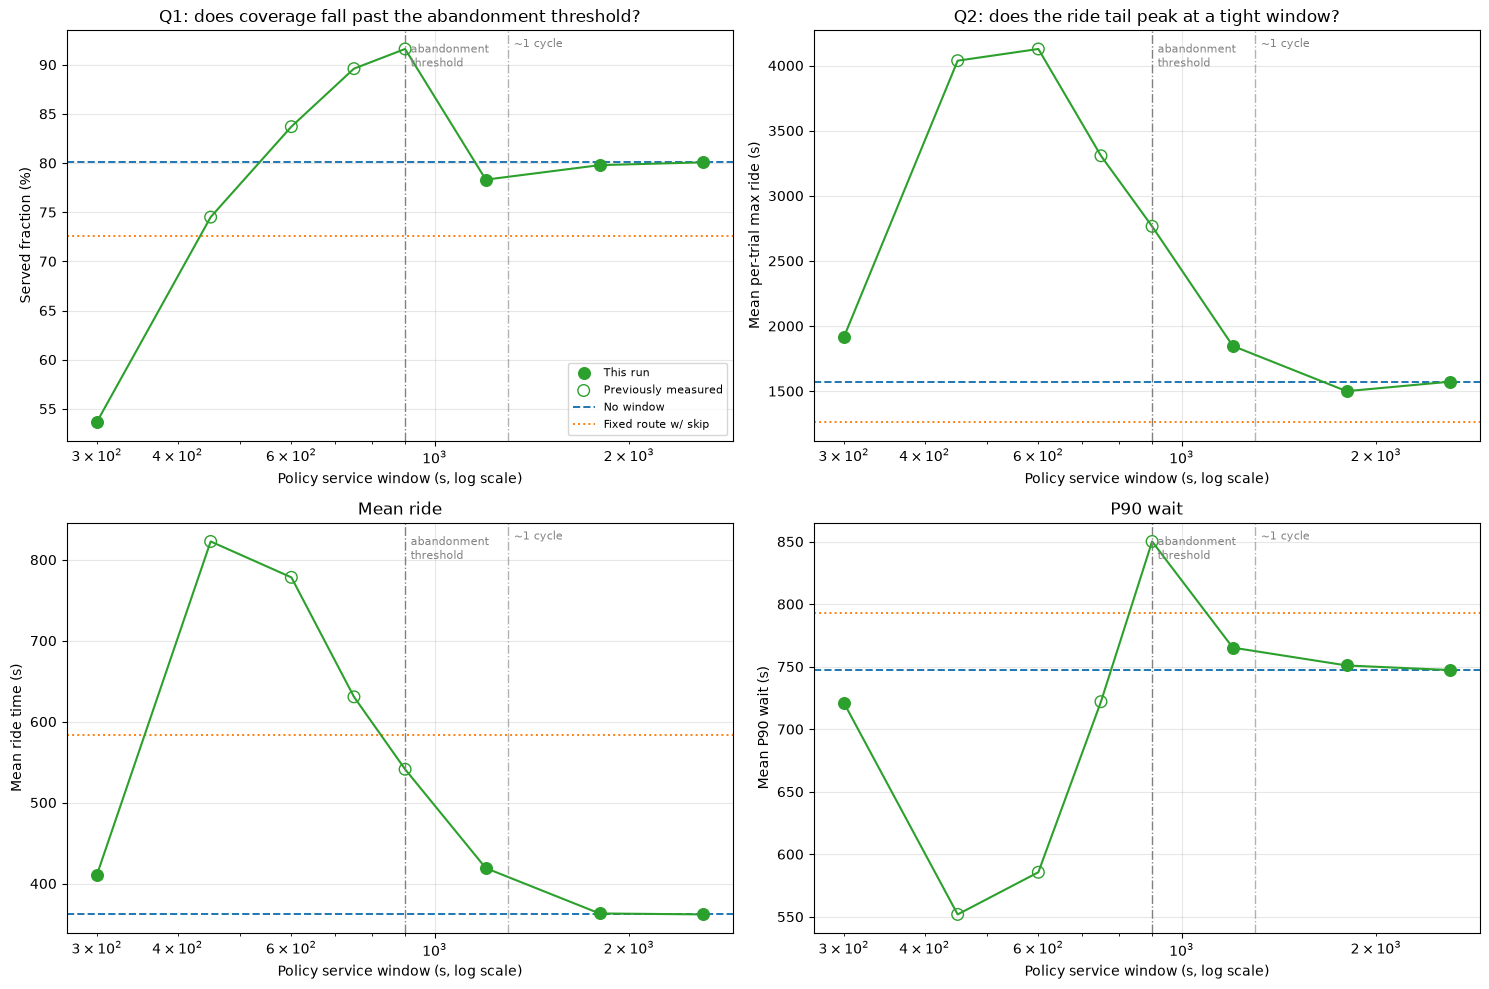

In [5]:
def _mean_of(trials, extract):
    """Mean of extract() over trials, skipping runs where it is undefined."""
    values = [v for v in (extract(t) for t in trials) if v is not None]
    return statistics.fmean(values) if values else None


MEASURED = {
    "served": lambda ts: (
        None if _mean_of(ts, lambda t: t.kpi.served_fraction) is None
        else _mean_of(ts, lambda t: t.kpi.served_fraction) * 100.0
    ),
    "mean_wait": lambda ts: _mean_of(ts, lambda t: t.kpi.mean_wait_time),
    "p90_wait": lambda ts: _mean_of(ts, lambda t: t.kpi.p90_wait_time),
    "mean_ride": lambda ts: _mean_of(ts, lambda t: t.kpi.mean_ride_time),
    "max_ride": lambda ts: _mean_of(
        ts, lambda t: max(t.ride_times) if t.ride_times else None
    ),
}

# This run's points, keyed by window width.
new_points = {
    width: {
        metric: extract(summary.results[f"Window {int(width)}s"])
        for metric, extract in MEASURED.items()
    }
    for width in WINDOWS
}

# Previously measured windows (those with a finite width).
old_points = {
    ref["width"]: ref
    for ref in REFERENCE.values()
    if ref["width"] is not None
}


def plot_vs_width(ax, metric, ylabel, title):
    """Draw one metric against window width, new and reference together."""
    # A window tight enough to fulfil nothing leaves the metric undefined;
    # drop those points rather than letting matplotlib choke on a None.
    widths = [
        w for w in sorted(set(new_points) | set(old_points))
        if (new_points[w][metric] if w in new_points
            else old_points[w][metric]) is not None
    ]
    values = [
        new_points[w][metric] if w in new_points else old_points[w][metric]
        for w in widths
    ]
    ax.plot(widths, values, "-", color="tab:green", zorder=2)
    ax.scatter(
        [w for w in widths if w in new_points],
        [new_points[w][metric] for w in widths if w in new_points],
        marker="o", color="tab:green", s=70, zorder=3, label="This run",
    )
    ax.scatter(
        [w for w in widths if w not in new_points],
        [old_points[w][metric] for w in widths if w not in new_points],
        marker="o", facecolors="none", edgecolors="tab:green", s=70,
        zorder=3, label="Previously measured",
    )

    for label, colour, style in (
        ("No window", "tab:blue", "--"),
        ("Fixed route w/ skip", "tab:orange", ":"),
    ):
        ax.axhline(
            REFERENCE[label][metric], color=colour, linestyle=style,
            linewidth=1.4, label=label, zorder=1,
        )

    ax.axvline(ABANDON_S, color="grey", linestyle="-.", linewidth=1.0)
    ax.annotate(
        "abandonment\nthreshold", (ABANDON_S, ax.get_ylim()[1]),
        textcoords="offset points", xytext=(4, -26), fontsize=8,
        color="grey",
    )
    ax.axvline(CYCLE_S, color="grey", linestyle="-.", linewidth=1.0, alpha=0.6)
    ax.annotate(
        "~1 cycle", (CYCLE_S, ax.get_ylim()[1]),
        textcoords="offset points", xytext=(4, -12), fontsize=8, color="grey",
    )

    ax.set_xscale("log")
    ax.set_xlabel("Policy service window (s, log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_vs_width(
    axes[0][0], "served", "Served fraction (%)",
    "Q1: does coverage fall past the abandonment threshold?",
)
plot_vs_width(
    axes[0][1], "max_ride", "Mean per-trial max ride (s)",
    "Q2: does the ride tail peak at a tight window?",
)
plot_vs_width(axes[1][0], "mean_ride", "Mean ride time (s)", "Mean ride")
plot_vs_width(axes[1][1], "p90_wait", "Mean P90 wait (s)", "P90 wait")
axes[0][0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 5. The coverage / ride-tail frontier

The same points replotted as a trade-off, which is how an operating point
would actually be chosen. Skip-stop and the unbounded window are the two
anchors: skip-stop has the bounded ride tail, the unbounded window has the
best ride quality of any insertion variant.

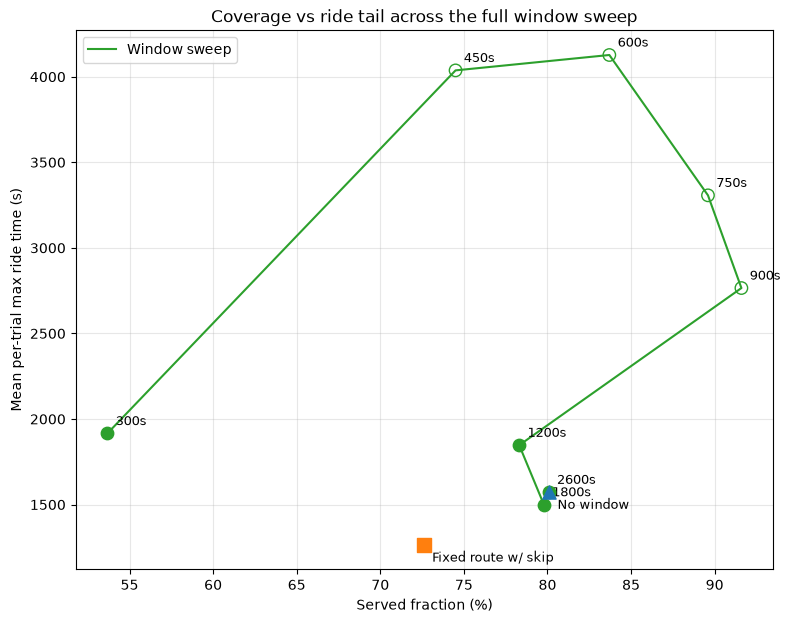

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))

ordered = [
    w for w in sorted(set(new_points) | set(old_points))
    if (new_points[w] if w in new_points else old_points[w])["served"]
    is not None
    and (new_points[w] if w in new_points else old_points[w])["max_ride"]
    is not None
]
ax.plot(
    [
        (new_points[w] if w in new_points else old_points[w])["served"]
        for w in ordered
    ],
    [
        (new_points[w] if w in new_points else old_points[w])["max_ride"]
        for w in ordered
    ],
    "-", color="tab:green", zorder=2, label="Window sweep",
)

for width in ordered:
    point = new_points[width] if width in new_points else old_points[width]
    is_new = width in new_points
    ax.scatter(
        point["served"], point["max_ride"], marker="o", s=80, zorder=3,
        color="tab:green" if is_new else "none",
        edgecolors="tab:green",
    )
    ax.annotate(
        f"{int(width)}s", (point["served"], point["max_ride"]),
        textcoords="offset points", xytext=(6, 6), fontsize=9,
    )

for label, colour, marker in (
    ("No window", "tab:blue", "^"),
    ("Fixed route w/ skip", "tab:orange", "s"),
):
    ref = REFERENCE[label]
    ax.scatter(
        ref["served"], ref["max_ride"], marker=marker, color=colour,
        s=90, zorder=4,
    )
    ax.annotate(
        label, (ref["served"], ref["max_ride"]),
        textcoords="offset points", xytext=(6, -12), fontsize=9,
    )

ax.set_xlabel("Served fraction (%)")
ax.set_ylabel("Mean per-trial max ride time (s)")
ax.set_title("Coverage vs ride tail across the full window sweep")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## 6. Aggregate KPIs and wait distributions

Only the four new columns appear here — these helpers read `summary.results`,
which holds this run alone.

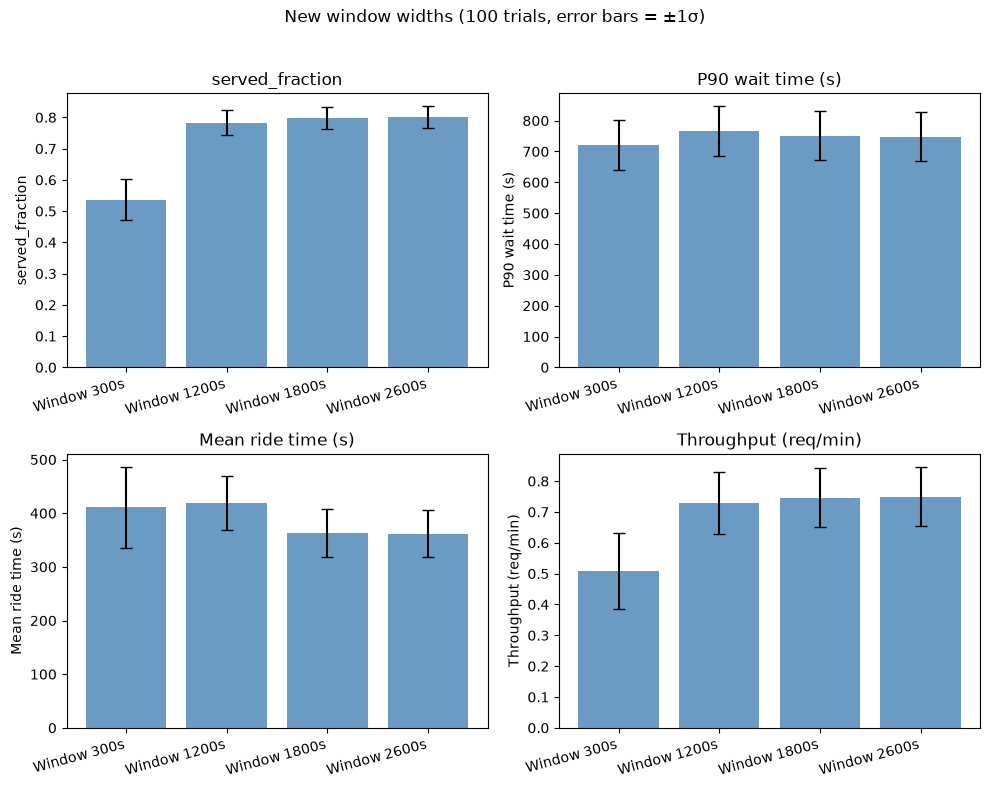

In [7]:
fig = plot_kpi_bars(
    summary.results,
    fields=["served_fraction", "p90_wait_time", "mean_ride_time",
            "throughput"],
    title=f"New window widths ({N_TRIALS} trials, error bars = ±1σ)",
)

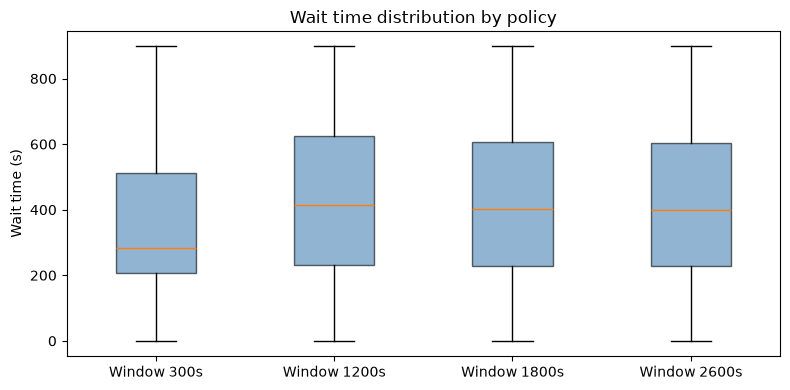

In [8]:
fig = plot_wait_distribution(summary.results)

## What to look for

Both questions have a falsifiable answer, so this notebook can come out
against the proposed explanations. That is the point of running it.

**Q1 — triage.** Confirmed if served fraction declines monotonically from
91.6% at 900s through 1200 / 1800 / 2600 toward the no-window line at 80.1%,
flattening once past the ~1300s cycle mark. Refuted if it stays flat out to
1800s (the window is not what causes the no-window drop — look for another
cause, e.g. the insertion search itself degrading on a longer schedule), or
if it is non-monotone out here (something more complicated is happening).

**Q2 — the ride-tail inversion.** Confirmed if the 300s column posts a max
ride *below* W450's 4037s, giving a clean inverted-U peaking somewhere around
500–650s. Refuted if 300s comes in *above* 4037s, in which case max ride is
simply monotone-decreasing in window width and the "constraint fights the
objective" story is wrong.

**Also worth reading off:**

- **Does 300s give the best mean wait anywhere?** W450 held it at 353s. If
  300s beats that while collapsing coverage, the tight end is a genuine
  wait-optimising operating point rather than just a bad window.
- **Where does the wide end converge?** If 2600s is indistinguishable from
  no window, the effective window range is roughly 300–1500s and there is no
  reason to sweep wider on this map.
- **Is there a better operating point than 750s?** That was the balanced pick
  from the previous run (89.6% served, P90 722s, mean ride 631s). Nothing in
  the new range is expected to beat it on coverage, but 1200s might trade a
  little coverage for a materially better ride tail.

### A caveat on reproducibility

Re-running in a fresh kernel can shift numbers slightly even with the seeds
fixed: Python randomizes string hashing per process, and several policies
break ties with `min()` over a `set[str]`. Set `PYTHONHASHSEED=0` before
launching Jupyter if bit-reproducible output across sessions matters. This
also applies to comparing against the `REFERENCE` values above, which were
produced in a different process.